## 오토인코더


In [1]:
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import FashionMNIST
from torchvision.transforms import v2

SEED = 42
torch.manual_seed(SEED)


### 오토인코더란

오토인코더(autoencoder)는 데이터를 복원하도록 학습해 데이터의 특징을 얻는 신경망이다. 학습한 특징이나 복원 결과를 이용해 데이터를 작은 표현으로 바꾸고, 잡음을 제거하거나, 평소와 다른 데이터를 찾아내는 데 사용한다.

품목 라벨 없이 입력 자체를 복원 목표로 삼아 특징을 학습하는 비지도학습 방법이다.

| 활용 | 학습한 결과를 사용하는 방법 |
| --- | --- |
| 차원 축소·특징 추출 | 많은 픽셀이나 측정값을 작은 특징 벡터로 표현한다. 이 벡터로 비슷한 데이터를 검색하거나, 군집화·예측 모델의 입력으로 사용한다 |
| 잡음 제거 | 잡음이 섞인 데이터를 입력으로, 깨끗한 데이터를 복원 목표로 학습한다. 학습 후에는 잡음이 있는 이미지나 신호에서 깨끗한 값을 복원한다 |
| 이상 탐지 | 정상 데이터를 복원하도록 학습한 뒤, 새 데이터의 복원 오차를 이상 점수로 사용한다. 센서의 이상 신호처럼 정상 패턴에서 벗어난 후보를 찾는 데 활용한다 |

특징 벡터의 유용성은 사용하는 분석 작업에서 평가하며, 이상 탐지의 판단 기준은 정상·이상 데이터의 복원 오차를 검증해 정한다.

이 이미지 복원 문제는 차원 축소에 해당한다. 이미지의 픽셀 784개를 작은 잠재 표현으로 바꾸고, 그 표현에서 원본을 복원한다. 원본과 복원 픽셀의 차이를 줄이면서 제한된 값에 이미지 정보를 담는 방법을 학습한다.

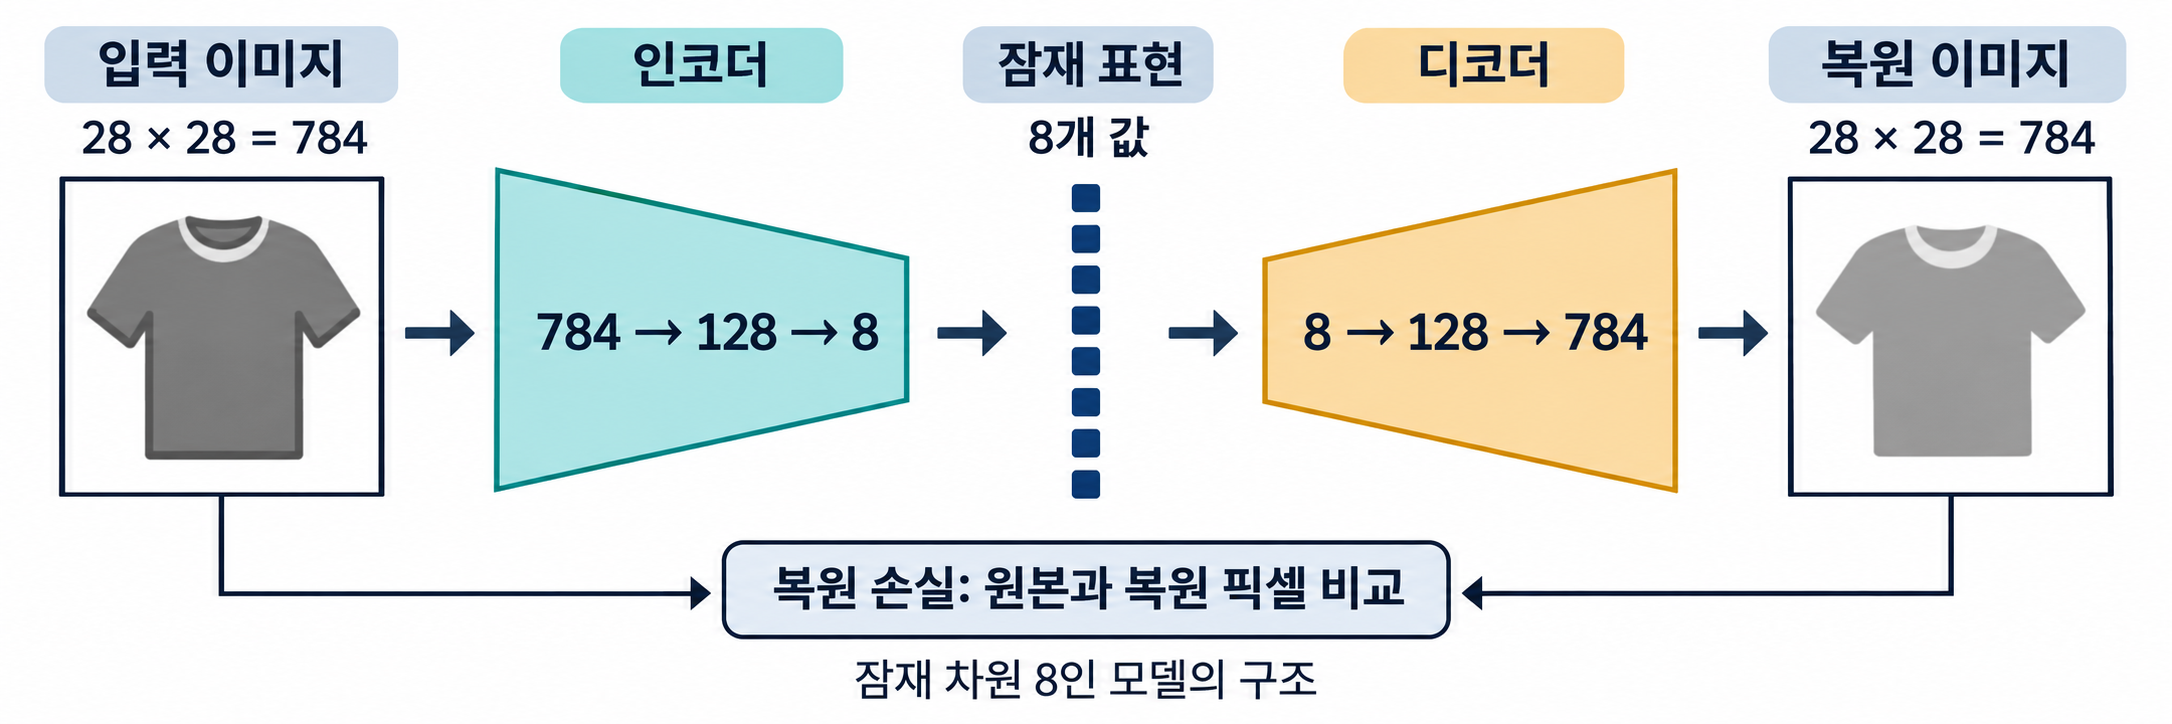

| 구성 | 역할 |
| --- | --- |
| 인코더(encoder) | 입력을 복원에 필요한 정보가 담긴 벡터로 변환한다 |
| 잠재 표현(latent representation) | 인코더가 만든 중간 벡터로, 입력의 특징을 담는다 |
| 디코더(decoder) | 잠재 표현에서 원래 입력과 같은 모양의 출력을 만든다 |

잠재 차원은 잠재 표현에 들어가는 숫자의 개수다. 입력보다 잠재 차원을 작게 두면 복원에 사용할 수 있는 표현이 제한된다. 이 제약 아래에서 복원 오차를 줄이며 이미지의 형태와 픽셀 관계를 학습한다.


### 의류 이미지 복원

28×28 흑백 이미지의 픽셀 784개를 작은 벡터로 압축한 뒤 다시 784개 픽셀로 복원하는 문제다.
원본과 복원 이미지를 비교하면 전체 형태와 경계가 얼마나 유지되었는지 확인할 수 있다.

### Fashion-MNIST 데이터 불러오기

Fashion-MNIST는 의류·신발·가방의 28×28 흑백 이미지이며, 품목은 10개다. 공식 학습 데이터는 60,000장, 테스트 데이터는 10,000장이다.
픽셀값을 0~1로 변환하며, 입력 이미지 자체를 복원 정답으로 사용한다. 품목 라벨은 데이터 분리와 이미지 표시에 사용한다.


In [2]:
transform = v2.Compose([
    # (채널, 높이, 너비) = (1, 28, 28)인 이미지 텐서로 변환한다.
    v2.ToImage(),

    # float32로 바꾸고 픽셀값을 0~1로 맞춘다.
    v2.ToDtype(torch.float32, scale=True),
])

fashion_train = FashionMNIST(root="image_data", train=True, download=True, transform=transform)
fashion_test = FashionMNIST(root="image_data", train=False, download=True, transform=transform)
classes = fashion_train.classes


### 실습 데이터 준비

학습 6,000장·검증 1,000장·테스트 1,000장을 품목별 비율과 난수 시드 42를 유지해 선택한다. 모든 실험에 같은 분할과 전처리를 사용한다.


In [3]:
train_labels = fashion_train.targets.numpy()
train_indices, remaining_indices = train_test_split(
    np.arange(len(fashion_train)), train_size=6000, stratify=train_labels, random_state=SEED,
)
val_indices, _ = train_test_split(
    remaining_indices, train_size=1000, stratify=train_labels[remaining_indices], random_state=SEED,
)
test_indices, _ = train_test_split(
    np.arange(len(fashion_test)), train_size=1000,
    stratify=fashion_test.targets.numpy(), random_state=SEED,
)

# 선택한 인덱스로 데이터셋을 구성하며, 이미지를 꺼낼 때 transform을 적용한다.
train_dataset = Subset(fashion_train, train_indices.tolist())
val_dataset = Subset(fashion_train, val_indices.tolist())
test_dataset = Subset(fashion_test, test_indices.tolist())

print("학습·검증·테스트 이미지 수:", len(train_dataset), len(val_dataset), len(test_dataset))


학습·검증·테스트 이미지 수: 6000 1000 1000


### 원본 이미지 살펴보기

학습 이미지 6장을 확대해 소매·바지통의 모양과 물체의 경계를 살펴본다.
원본은 28×28 픽셀이므로 관찰은 전체 형태와 밝기 차이를 중심으로 한다.


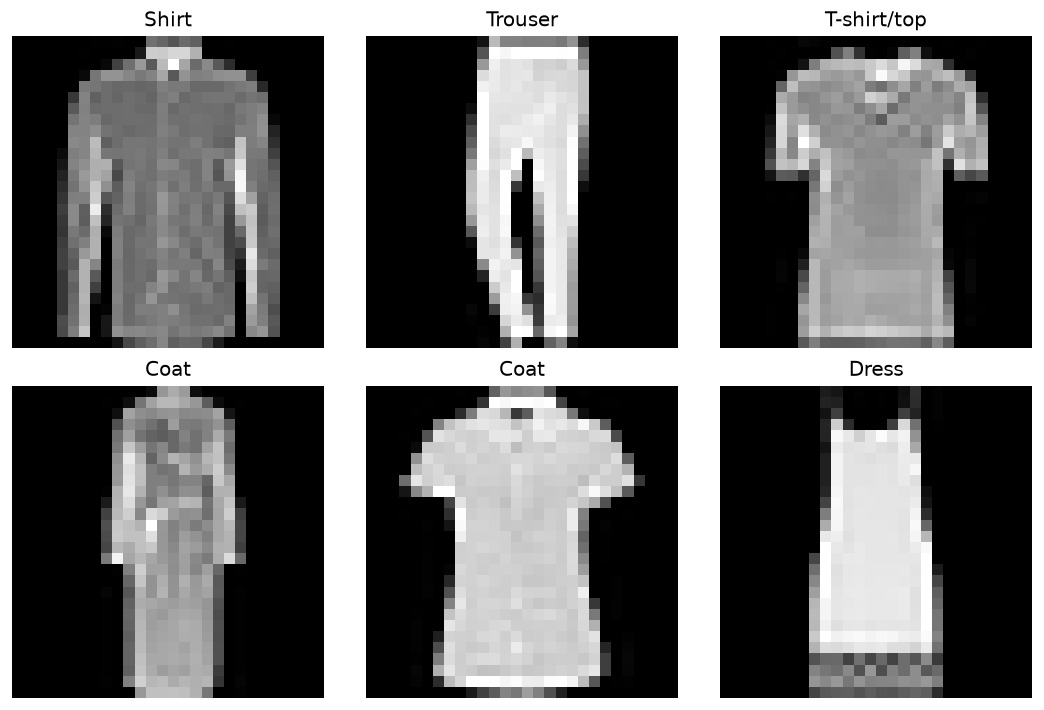

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6), dpi=120)
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # nearest: 픽셀 사이의 밝기를 보간하지 않고 원래 픽셀을 확대해 표시한다.
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 압축과 복원을 수행하는 신경망

### 인코더와 디코더 구성

인코더와 디코더에 각각 뉴런 128개인 은닉층 하나를 둔다.

```text
인코더: 784 → 128 → 8
디코더:   8 → 128 → 784
```

입력과 출력의 784는 이미지 크기 28×28에 맞춘 값이며, 은닉층의 128과 잠재 차원의 8은 모델을 구성할 때 정하는 값이다.

은닉층 뒤에는 ReLU를 적용해 비선형 관계를 표현한다. 잠재 표현을 만드는 층에는 활성화 함수를 두지 않아 양수와 음수를 모두 사용할 수 있다.
디코더의 마지막에는 Sigmoid를 적용해 복원 픽셀을 원본과 같은 0~1 범위로 맞춘다.

`nn.Module`은 PyTorch 신경망의 기본 클래스다. 이를 상속받으면 `self.encoder`, `self.decoder`처럼 속성으로 지정한 층과 그 파라미터를 모델의 일부로 관리할 수 있다.

`forward`에는 입력을 받아 출력을 만드는 계산 순서를 정의한다. `model(inputs)`를 호출하면 `nn.Module`의 호출 처리를 통해 `forward(inputs)`가 실행된다. 여기서는 입력을 인코더에 전달해 잠재 표현을 만들고, 이를 디코더에 전달해 복원 이미지를 반환한다.


In [5]:
class ImageAutoencoder(nn.Module):
    def __init__(self, latent_dim=8):
        super().__init__()

        # Sequential: 입력을 나열한 층에 차례로 전달한다.
        self.encoder = nn.Sequential(
            # 마지막 축을 픽셀 784개에서 은닉 값 128개로 바꾼다.
            nn.Linear(784, 128),
            nn.ReLU(),
            # latent_dim: 잠재 표현의 차원 수
            nn.Linear(128, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid(),
        )

    def forward(self, inputs):
        # (배치, 784) → (배치, latent_dim)
        latent = self.encoder(inputs)

        # (배치, latent_dim) → (배치, 784)
        return self.decoder(latent)


### 인코더에 전달할 이미지 펼치기

인코더의 첫 층 `nn.Linear(784, 128)`은 이미지 한 장을 784개 값으로 받는다. 각 이미지의 `(1, 28, 28)` 모양을 `(784,)`로 펼쳐 이 층에 전달한다. 픽셀값과 순서는 유지되며, 복원 결과를 표시할 때는 다시 28×28로 배치한다.


In [6]:
# stack: 이미지들을 (이미지 수, 1, 28, 28)로 묶는다.
# flatten(1): 이미지 수 축을 유지하고 각 이미지를 784개 값으로 펼친다.
train_images = torch.stack([image for image, _ in train_dataset]).flatten(1)
val_images = torch.stack([image for image, _ in val_dataset]).flatten(1)
test_images = torch.stack([image for image, _ in test_dataset]).flatten(1)
print("학습·검증·테스트 입력 모양:", train_images.shape, val_images.shape, test_images.shape)


학습·검증·테스트 입력 모양: torch.Size([6000, 784]) torch.Size([1000, 784]) torch.Size([1000, 784])


### 복원 손실 계산

MSE(평균 제곱 오차)는 원본 픽셀과 복원 픽셀의 차이를 제곱한 뒤 평균 낸 값이다.
오토인코더는 배치 안의 모든 이미지와 픽셀에 대한 MSE를 줄이도록 학습한다.

$$
\mathrm{MSE} = \frac{1}{BP}\sum_{i=1}^{B}\sum_{j=1}^{P}\left(\hat{x}_{ij}-x_{ij}\right)^2
$$

$B$는 배치의 이미지 수, $P$는 이미지 한 장의 픽셀 수이며 여기서는 $P=784$다.
$x_{ij}$는 $i$번째 이미지의 $j$번째 원본 픽셀값, $\hat{x}_{ij}$는 같은 위치의 복원값이다.

원본 픽셀 세 개가 `[0.0, 0.5, 1.0]`, 복원값이 `[0.1, 0.4, 0.8]`이면 제곱 오차는 `[0.01, 0.01, 0.04]`이고 평균은 0.02다.
같은 평가 이미지에서 MSE가 작을수록 픽셀 값이 원본에 가깝다. 전체 평균과 함께 실제 이미지의 형태와 경계도 확인한다.


## 이미지 복원 학습

### 학습 이미지를 배치로 묶기

이미지를 배치로 전달하고, 입력 이미지 자체를 복원 정답으로 사용한다. 두 잠재 차원 비교에서 같은 배치 순서를 사용하도록 셔플 시드를 고정한다.


In [7]:
BATCH_SIZE = 128

def make_train_loader():
    # shuffle=True로 순서를 섞고, generator의 시드로 실험별 배치 순서를 맞춘다.
    return DataLoader(
        train_images, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

batch_inputs = next(iter(make_train_loader()))
print("배치 입력:", batch_inputs.shape)


배치 입력: torch.Size([128, 784])


### 복원 오차 평가

가중치를 갱신하지 않고 평가 이미지의 전체 픽셀 MSE를 계산한다.
마지막 배치의 이미지 수가 적어도 각 픽셀이 같은 비중을 갖도록 제곱 오차의 합을 전체 픽셀 수로 나눈다.


In [9]:
# no_grad: 평가에서는 기울기 계산 기록을 만들지 않는다.
@torch.no_grad()
def reconstruction_mse(model, images):
    model.eval()
    loader = DataLoader(images, batch_size=256)
    squared_error_sum, pixel_count = 0.0, 0

    for inputs in loader:
        restored = model(inputs)
        squared_error_sum += (restored - inputs).square().sum().item()

        # 배치 안의 전체 픽셀 수
        pixel_count += inputs.numel()
    return squared_error_sum / pixel_count


### 반복 학습과 최적 가중치 보관

Adam으로 12에포크 학습하며 매 에포크 학습·검증 MSE를 표로 기록한다.
학습이 끝나면 검증 MSE가 가장 낮았던 에포크의 가중치로 복원한다.


In [ ]:
def fit_autoencoder(latent_dim, epochs=12):
    torch.manual_seed(SEED)
    model = ImageAutoencoder(latent_dim=latent_dim)
    loader = make_train_loader()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # MSELoss: 복원값과 원본의 모든 픽셀에 대한 제곱 오차 평균을 계산한다.
    loss_function = nn.MSELoss()

    best_loss, best_state = float("inf"), None
    history = []

    for epoch in range(epochs):
        model.train()
        loss_sum, image_count = 0.0, 0
        for inputs in loader:
            restored = model(inputs)

            # 입력 이미지 자체를 복원 정답으로 사용한다.
            loss = loss_function(restored, inputs)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # 배치별 평균 손실에 이미지 수를 곱해 마지막 작은 배치도 같은 비중으로 반영한다.
            loss_sum += loss.item() * len(inputs)
            image_count += len(inputs)

        val_mse = reconstruction_mse(model, val_images)
        history.append({
            "epoch": epoch + 1,
            "train_MSE": loss_sum / image_count,
            "val_MSE": val_mse,
        })
        if val_mse < best_loss:
            best_loss = val_mse

            # 현재 가중치와 별도로 복사해 보관한다.
            best_state = deepcopy(model.state_dict())
        print(f"dim={latent_dim}, epoch={epoch+1}, val_MSE={val_mse:.5f}")

    # 검증 손실이 가장 낮았던 가중치를 불러온다.
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history)


### 잠재 차원 8인 모델 학습

픽셀 784개를 잠재 값 8개로 표현하는 모델을 학습한다.
학습 손실은 에포크 안에서 가중치를 갱신하며 얻은 평균이고, 검증 손실은 해당 에포크 학습을 마친 가중치로 계산한 값이다.


In [11]:
model_8, history_8 = fit_autoencoder(latent_dim=8)
models = {"latent_8": model_8}
histories = {"latent_8": history_8}


dim=8, epoch=1, val_MSE=0.06112
dim=8, epoch=2, val_MSE=0.04373
dim=8, epoch=3, val_MSE=0.03474
dim=8, epoch=4, val_MSE=0.02934
dim=8, epoch=5, val_MSE=0.02670
dim=8, epoch=6, val_MSE=0.02517
dim=8, epoch=7, val_MSE=0.02425
dim=8, epoch=8, val_MSE=0.02335
dim=8, epoch=9, val_MSE=0.02274
dim=8, epoch=10, val_MSE=0.02234
dim=8, epoch=11, val_MSE=0.02175
dim=8, epoch=12, val_MSE=0.02138


## 잠재 차원에 따른 복원 비교

### 잠재 차원 바꾸기

잠재 차원을 8에서 32로 늘리면 이미지 한 장을 표현하는 값이 4배로 늘어난다. 압축의 제약이 줄어들어 형태와 경계 정보를 더 많이 담을 수 있고, 복원 오차가 줄어들 가능성이 커진다. 대신 이미지마다 저장하거나 전달할 잠재 값의 수는 많아진다.

잠재 표현에 연결된 인코더의 마지막 층과 디코더의 첫 층도 커지므로, 학습할 가중치 수와 계산량이 늘어난다. 표현의 자유도가 높아지면서 학습 이미지의 세부 특징에 과도하게 맞춰질 수도 있다. 새로운 이미지에서의 복원 성능은 검증 MSE와 복원 결과로 확인한다.

잠재 차원을 32로 바꾸어 학습하며, 학습·검증 이미지, 은닉층 크기, 배치 순서, 학습률과 에포크 수는 유지한다. 두 모델의 초기화 시드는 같으며, 층의 모양에 따라 만들어지는 가중치는 달라진다.


In [12]:
model_32, history_32 = fit_autoencoder(latent_dim=32)
models["latent_32"] = model_32
histories["latent_32"] = history_32


dim=32, epoch=1, val_MSE=0.06133
dim=32, epoch=2, val_MSE=0.04505
dim=32, epoch=3, val_MSE=0.03507
dim=32, epoch=4, val_MSE=0.02874
dim=32, epoch=5, val_MSE=0.02635
dim=32, epoch=6, val_MSE=0.02535
dim=32, epoch=7, val_MSE=0.02394
dim=32, epoch=8, val_MSE=0.02277
dim=32, epoch=9, val_MSE=0.02190
dim=32, epoch=10, val_MSE=0.02129
dim=32, epoch=11, val_MSE=0.02075
dim=32, epoch=12, val_MSE=0.02026


### 학습·검증 곡선 비교

가로축은 에포크, 세로축은 픽셀 MSE다. 두 그래프는 같은 세로축 범위를 사용한다.
학습·검증 오차의 변화와 두 곡선 사이의 간격을 비교한다. 학습 오차가 줄어드는 동안 검증 오차가 커지면 과적합의 신호일 수 있다.


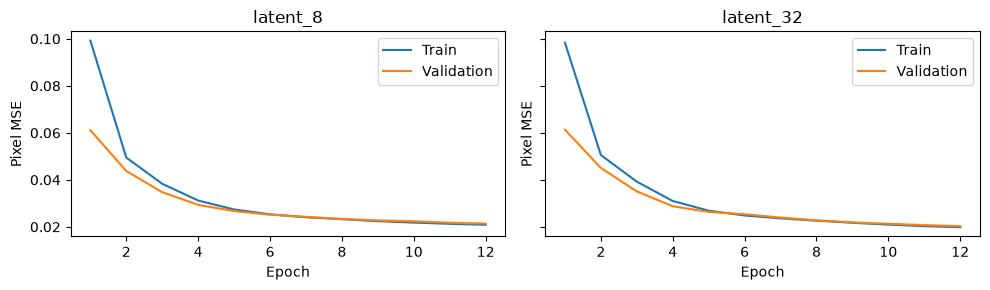

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, (name, history) in zip(axes, histories.items()):
    ax.plot(history["epoch"], history["train_MSE"], label="Train")
    ax.plot(history["epoch"], history["val_MSE"], label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Pixel MSE")
    ax.legend()
plt.tight_layout()
plt.show()


### 잠재 차원별 복원 오차 비교

두 모델의 학습·검증 MSE와 파라미터 수를 비교한다.
학습·검증 MSE는 각 모델의 검증 손실이 가장 낮았던 가중치를 불러온 뒤 다시 평가한 값이다.


,model,latent_dim,parameters,train_MSE,val_MSE
0,latent_8,8,203800,0.020603,0.021379
1,latent_32,32,209968,0.019459,0.020263


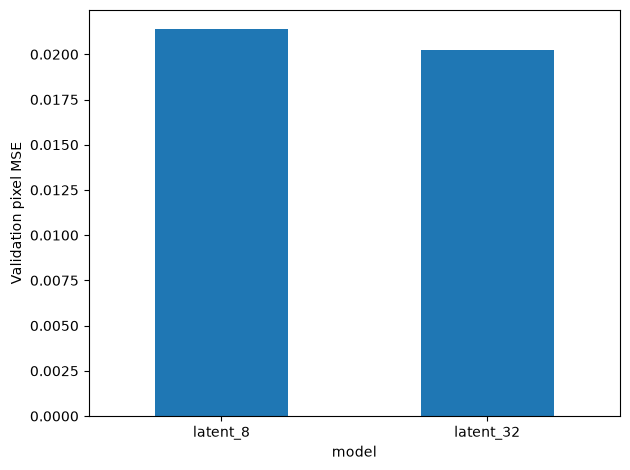

In [14]:
comparison_rows = []
for name, candidate in models.items():
    comparison_rows.append({
        "model": name,
        # 인코더 마지막 층의 출력 크기가 잠재 차원이다.
        "latent_dim": candidate.encoder[-1].out_features,

        # 각 파라미터 텐서의 원소 수를 합한다.
        "parameters": sum(parameter.numel() for parameter in candidate.parameters()),
        "train_MSE": reconstruction_mse(candidate, train_images),
        "val_MSE": reconstruction_mse(candidate, val_images),
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison)
comparison.plot.bar(x="model", y="val_MSE", legend=False, rot=0, ylabel="Validation pixel MSE")
plt.tight_layout()
plt.show()


### 같은 이미지의 복원 결과 비교

검증 구간에서 품목마다 첫 이미지 한 장을 골라 원본과 두 모델의 복원을 같은 열에 표시한다.
5개 품목씩 나누어 확대하고, 모든 이미지는 같은 밝기 범위로 표시한다.

원본의 형태와 경계가 각 모델에서 얼마나 유지되는지 비교한다.
검증 MSE와 함께 품목별 복원 결과의 선명도도 확인한다.


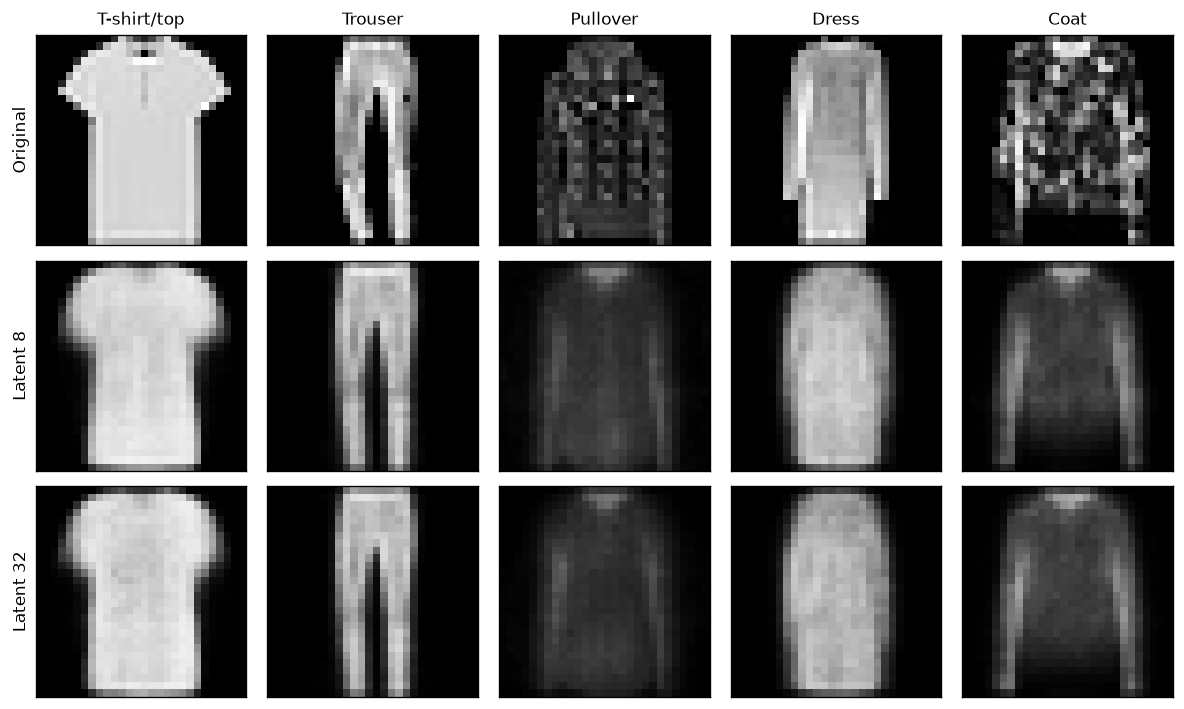

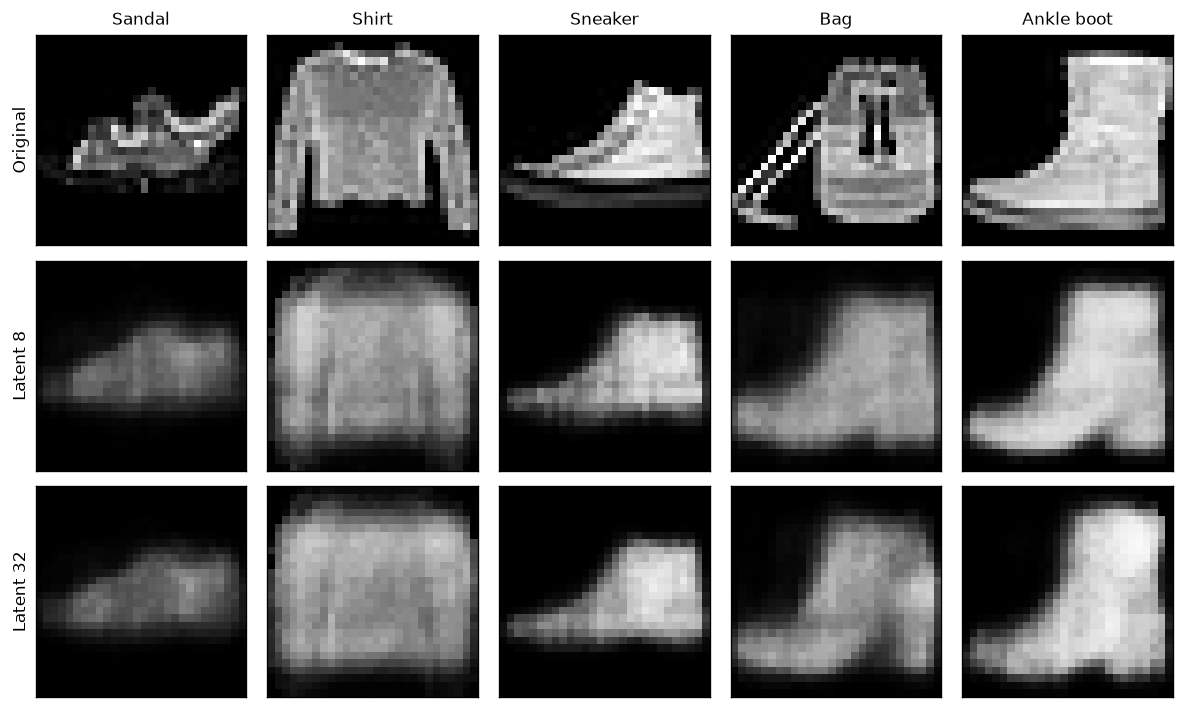

In [15]:
val_labels = train_labels[val_indices]

# flatnonzero: 조건을 만족하는 위치를 반환한다. 품목마다 첫 위치를 고른다.
show_indices = np.array([np.flatnonzero(val_labels == label)[0] for label in range(10)])
show_images = val_images[show_indices]
with torch.no_grad():
    restored_8 = model_8(show_images)
    restored_32 = model_32(show_images)

image_rows = [
    ("Original", show_images),
    ("Latent 8", restored_8),
    ("Latent 32", restored_32),
]
for start in range(0, 10, 5):
    fig, axes = plt.subplots(3, 5, figsize=(10, 6), dpi=120)
    for row, (name, images) in enumerate(image_rows):
        for column in range(5):
            index = start + column
            axes[row, column].imshow(
                images[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1,
                interpolation="nearest",
            )
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
            if row == 0:
                axes[row, column].set_title(classes[index], fontsize=10)
        axes[row, 0].set_ylabel(name)
    plt.tight_layout()
    plt.show()


### 잠재 표현과 복원의 한계

두 모델의 잠재 표현에는 원본 픽셀 수보다 적은 값이 들어간다. 제한된 표현과 학습 결과에 따라 가는 선이나 경계 정보가 손실될 수 있다.
MSE는 픽셀 밝기 차이를 평균 내므로 눈으로 중요하게 보는 형태와 세부 표현도 함께 확인해야 한다.
잠재 차원을 늘렸을 때의 효과는 같은 검증 데이터에서 실제로 계산한 오차와 복원 이미지로 판단한다.


## 모델 선택과 최종 평가

### 검증 결과로 모델 선택하기

두 오토인코더 중 검증 MSE가 가장 작은 모델을 선택한다.
값이 같으면 파라미터 수가 적은 모델을 선택한다. 테스트 이미지는 선택한 모델의 최종 평가에 사용한다.


In [16]:
selected_name = str(comparison.sort_values(["val_MSE", "parameters"]).iloc[0]["model"])
print("선택한 방법:", selected_name)


선택한 방법: latent_32


### 최종 테스트

선택한 방법으로 테스트 이미지의 픽셀 MSE를 계산한다.
이 결과는 Fashion-MNIST에서 선택한 테스트 이미지 1,000장에 대한 복원 성능이다. 검증 결과와 비교해 처음 보는 이미지에서도 복원 오차가 비슷하게 유지되는지 확인한다.


In [17]:
test_mse = reconstruction_mse(models[selected_name], test_images)
display(pd.DataFrame([{"model": selected_name, "test_MSE": test_mse}]))


,model,test_MSE
0,latent_32,0.019336


## 활용: 비슷한 이미지 검색

학습된 인코더는 이미지를 특징 벡터로 바꾸고, 최근접 이웃 검색은 이 벡터 사이의 거리가 가까운 이미지를 찾는다. K개의 가까운 이웃을 구하는 KNN의 원리를 이용하며, 여기서는 가까운 이미지 5장을 검색 결과로 반환한다. 검색에는 인코더의 출력만 사용한다.

### 잠재 표현으로 가까운 이미지 찾기

잠재 차원 32인 모델의 인코더로 학습 이미지 6,000장을 각각 32개 값으로 표현한다. 검색할 이미지는 학습 이미지와 겹치지 않는 검증 데이터의 첫 3장을 사용한다.

각 검색 이미지와 학습 이미지 사이의 유클리드 거리를 구하고, 거리가 작은 순서대로 5장을 선택한다. 유클리드 거리는 두 벡터의 같은 위치 값의 차이를 제곱해 더한 뒤 제곱근을 구한 값이다.


In [18]:
query_images = val_images[:3]

model_32.eval()
with torch.no_grad():
    # 이미지마다 32개 특징을 얻는다: (6000, 32), (3, 32).
    search_features = model_32.encoder(train_images)
    query_features = model_32.encoder(query_images)

    # cdist의 p=2: 두 벡터 집합 사이의 유클리드 거리. 결과는 (3, 6000)이다.
    distances = torch.cdist(query_features, search_features, p=2)

    # 각 검색 이미지에서 거리가 가장 작은 5개의 값과 학습 이미지 인덱스를 얻는다.
    # dim=1은 검색 대상 이미지 축이며, largest=False는 작은 값부터 선택한다.
    nearest_distances, nearest_indices = distances.topk(k=5, dim=1, largest=False)


### 검색 이미지와 결과

각 행의 첫 이미지는 검색 이미지이며, 오른쪽은 잠재 표현의 거리가 가까운 순서로 찾은 이미지 5장이다. 제목의 품목 이름은 데이터에 붙어 있는 라벨이고, 검색에는 사용하지 않는다.

잠재 표현은 원본의 픽셀을 복원하도록 학습되었으므로, 검색 결과에는 전체 형태와 밝기의 유사성도 반영된다. 표시된 거리는 같은 모델이 만든 특징 벡터 사이의 거리이며, 작을수록 해당 특징 공간에서 가깝다.

이 예시는 검색 이미지 3장으로 잠재 표현을 활용하는 방법을 보여 준다. 검색 품질을 평가하려면 검색할 이미지를 충분히 확보하고, 어떤 결과를 관련 있는 이미지로 볼지 기준을 정해 별도로 평가한다.


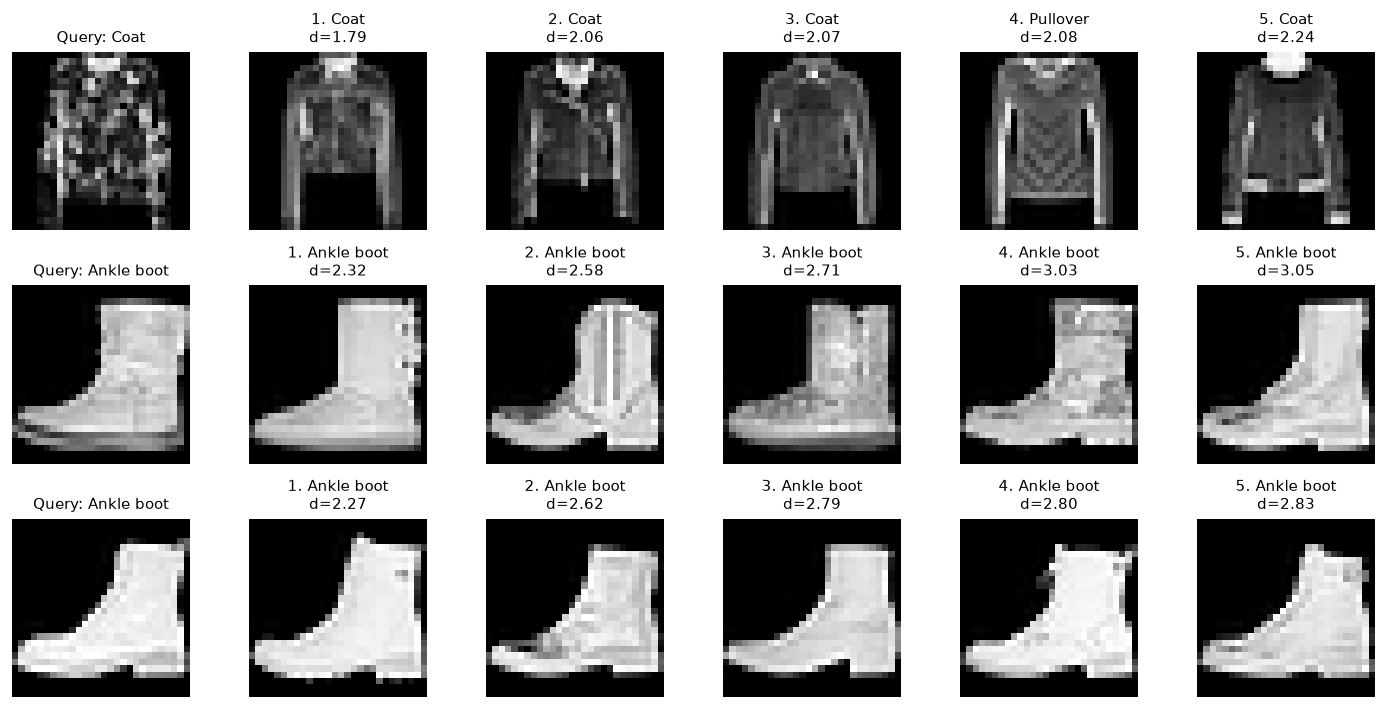

: 

In [ ]:
query_labels = train_labels[val_indices[:3]]
search_labels = train_labels[train_indices]

fig, axes = plt.subplots(3, 6, figsize=(12, 6), dpi=120)
for row in range(3):
    axes[row, 0].imshow(
        query_images[row].reshape(28, 28), cmap="gray", vmin=0, vmax=1,
        interpolation="nearest",
    )
    axes[row, 0].set_title(f"Query: {classes[query_labels[row]]}", fontsize=9)
    axes[row, 0].axis("off")

    for rank in range(5):
        index = nearest_indices[row, rank].item()
        distance = nearest_distances[row, rank].item()
        ax = axes[row, rank + 1]
        ax.imshow(
            train_images[index].reshape(28, 28), cmap="gray", vmin=0, vmax=1,
            interpolation="nearest",
        )
        ax.set_title(f"{rank + 1}. {classes[search_labels[index]]}\nd={distance:.2f}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()
